In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

In [3]:
print("--- Head ---")
display(df.head())

--- Head ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("\n--- Shape ---")
print(df.shape)


--- Shape ---
(7043, 21)


In [5]:
print("\n--- Data Types ---")
print(df.dtypes)


--- Data Types ---
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [6]:
print("\n--- Number of Duplicate Rows ---")
print(df.duplicated().sum())


--- Number of Duplicate Rows ---
0


In [7]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

df = df.drop(columns=['customerID'])

print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())
print("\nDataFrame Info:")
display(df.info())


Missing values in TotalCharges: 11

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   obj

None

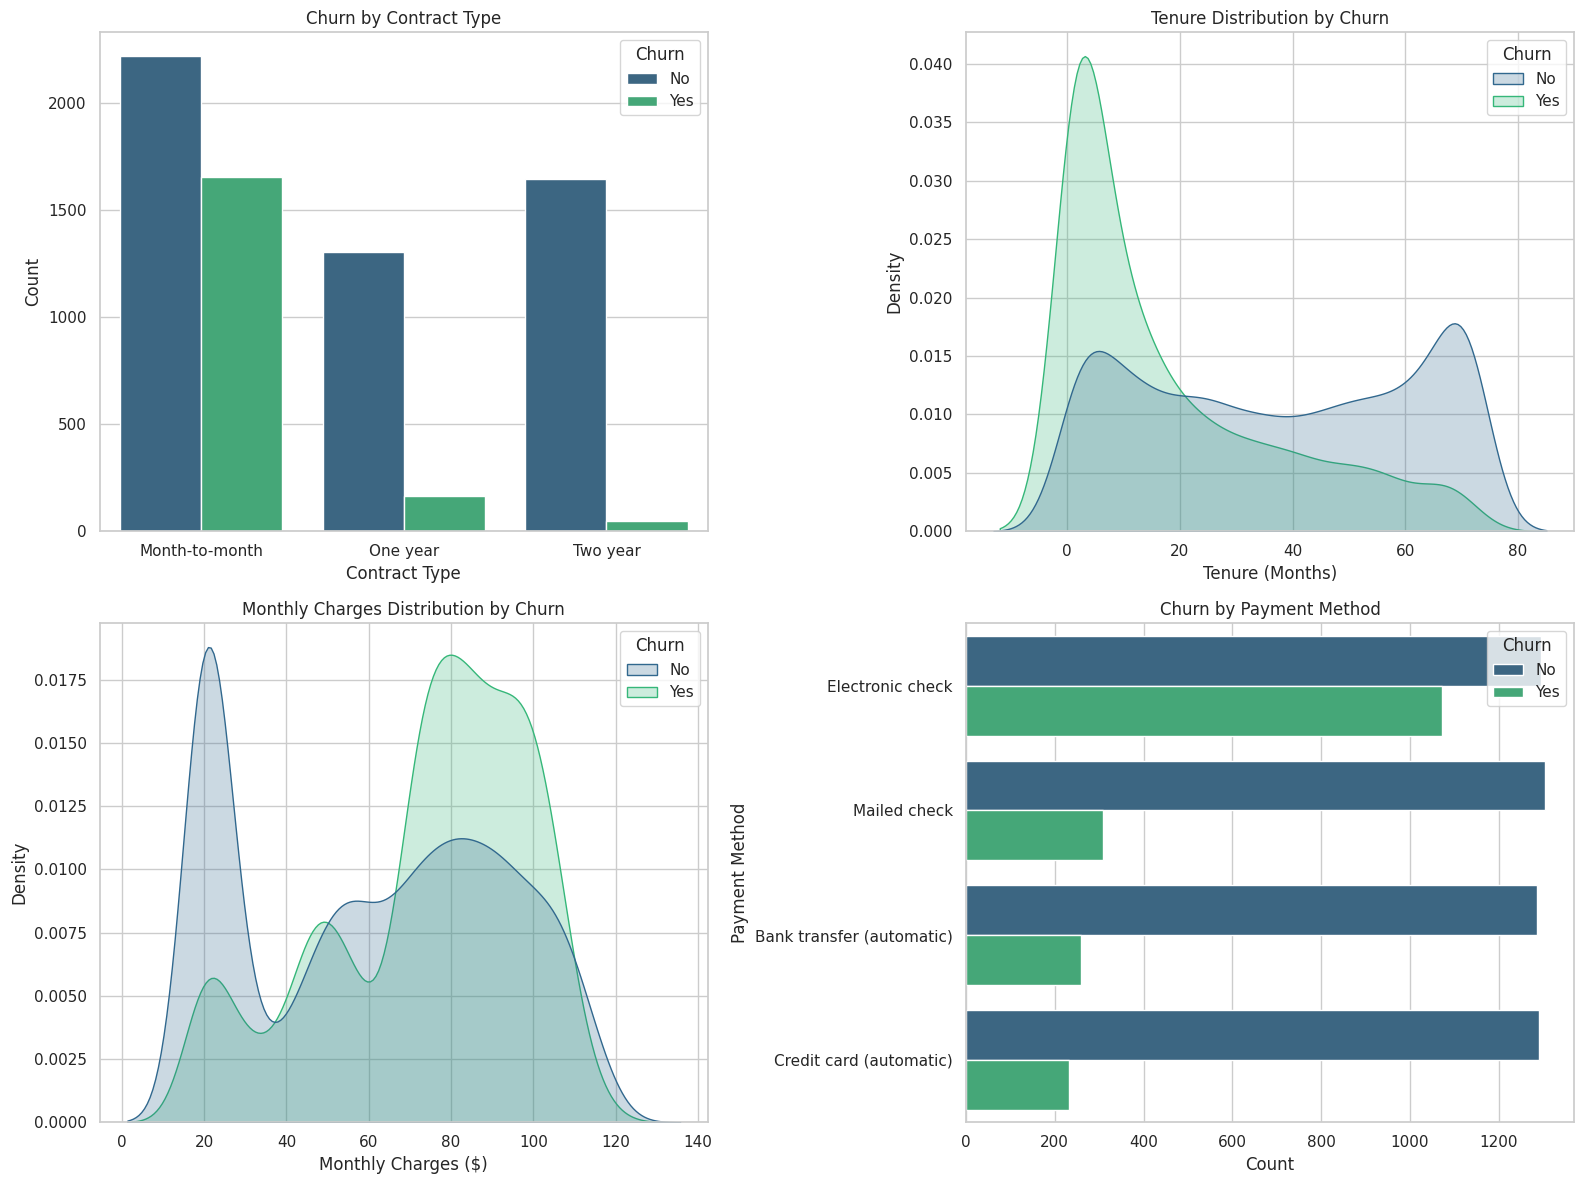

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Churn by Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Churn by Contract Type')
axes[0, 0].set_xlabel('Contract Type')
axes[0, 0].set_ylabel('Count')

# 2. Churn by Tenure
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Tenure Distribution by Churn')
axes[0, 1].set_xlabel('Tenure (Months)')
axes[0, 1].set_ylabel('Density')

# 3. Churn by Monthly Charges
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Monthly Charges Distribution by Churn')
axes[1, 0].set_xlabel('Monthly Charges ($)')
axes[1, 0].set_ylabel('Density')

# 4. Churn by Payment Method
sns.countplot(data=df, y='PaymentMethod', hue='Churn', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Churn by Payment Method')
axes[1, 1].set_xlabel('Count')
axes[1, 1].set_ylabel('Payment Method')

plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)
print("\nTrain class distribution:\n", y_train.value_counts(normalize=True))
print("\nTest class distribution:\n", y_test.value_counts(normalize=True))

Training set shape: (5634, 19) (5634,)
Testing set shape: (1409, 19) (1409,)

Train class distribution:
 Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64

Test class distribution:
 Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

# Create the preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ]
)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

encoded_cat_features = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_features = numeric_features + list(encoded_cat_features)

X_train_preprocessed_df = pd.DataFrame(X_train_preprocessed, columns=all_features, index=X_train.index)
X_test_preprocessed_df = pd.DataFrame(X_test_preprocessed, columns=all_features, index=X_test.index)

print(f"\nProcessed training set shape: {X_train_preprocessed_df.shape}")
display(X_train_preprocessed_df.head())

Numeric Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Processed training set shape: (5634, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,-0.441773,0.102371,-0.521976,-0.263695,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,-0.441773,-0.711743,0.337478,-0.505076,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,-0.441773,-0.793155,-0.809013,-0.751328,1.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3867,-0.441773,-0.263980,0.284384,-0.174159,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
3810,-0.441773,-1.281624,-0.676279,-0.990822,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Handle missing values in TotalCharges (if any are introduced after preprocessing/imputation)
# Simple imputation for the 11 missing values we observed in TotalCharges:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
X_train_clean = imputer.fit_transform(X_train_preprocessed_df)
X_test_clean = imputer.transform(X_test_preprocessed_df)

y_train_encoded = y_train.map({'Yes': 1, 'No': 0})
y_test_encoded = y_test.map({'Yes': 1, 'No': 0})

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

for name, model in models.items():

    model.fit(X_train_clean, y_train_encoded)

    y_pred = model.predict(X_test_clean)

    print(f"================ {name} ================")
    print(f"Accuracy: {accuracy_score(y_test_encoded, y_pred):.4f}")
    print(classification_report(y_test_encoded, y_pred))
    print("\n")

================ Logistic Regression ================
Accuracy: 0.8055
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



================ Decision Tree ================
Accuracy: 0.7942
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.63      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



================ Random Forest ================
Accuracy: 0.7857
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.4

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

balanced_models = {
    "Logistic Regression (Balanced)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "Decision Tree (Balanced)": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    "Random Forest (Balanced)": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
}

recall_comparison = {}

for name, model in balanced_models.items():
    model.fit(X_train_clean, y_train_encoded)
    y_pred = model.predict(X_test_clean)

    report = classification_report(y_test_encoded, y_pred, output_dict=True)

    recall_0 = report['0']['recall']
    recall_1 = report['1']['recall']
    accuracy = report['accuracy']

    recall_comparison[name] = {
        "Accuracy": accuracy,
        "Recall (No Churn)": recall_0,
        "Recall (Churn)": recall_1
    }

    print(f"================ {name} ================")
    print(f"Accuracy: {accuracy:.4f}")
    print(classification_report(y_test_encoded, y_pred))
    print("\n")

# Display the final summary comparison DataFrame
print("=== Summary Comparison (Recall Focus) ===")
summary_df = pd.DataFrame(recall_comparison).T
display(summary_df)

================ Logistic Regression (Balanced) ================
Accuracy: 0.7388
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



================ Decision Tree (Balanced) ================
Accuracy: 0.7346
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1035
           1       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409



================ Random Forest (Balanced) ================
Accuracy: 0.7878
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035

,Accuracy,Recall (No Churn),Recall (Churn)
Logistic Regression (Balanced),0.738822,0.722705,0.783422
Decision Tree (Balanced),0.734564,0.708213,0.807487
Random Forest (Balanced),0.787793,0.892754,0.497326


In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample', None]
}

# Initialize the base Random Forest
rf_base = RandomForestClassifier(random_state=42)

grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train_clean, y_train_encoded)

print("Best parameters found for Random Forest:", grid_search_rf.best_params_)
print(f"Best cross-validation Accuracy score: {grid_search_rf.best_score_:.4f}")

best_rf_model = grid_search_rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test_clean)

print("\n================ Best Random Forest (Tuned) ================")
print(f"Test Accuracy: {accuracy_score(y_test_encoded, y_pred_rf):.4f}")
print(classification_report(y_test_encoded, y_pred_rf))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters found for Random Forest: {'class_weight': None, 'max_depth': 8, 'min_samples_split': 10, 'n_estimators': 100}
Best cross-validation Accuracy score: 0.8009

================ Best Random Forest (Tuned) ================
Test Accuracy: 0.8027
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.68      0.49      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



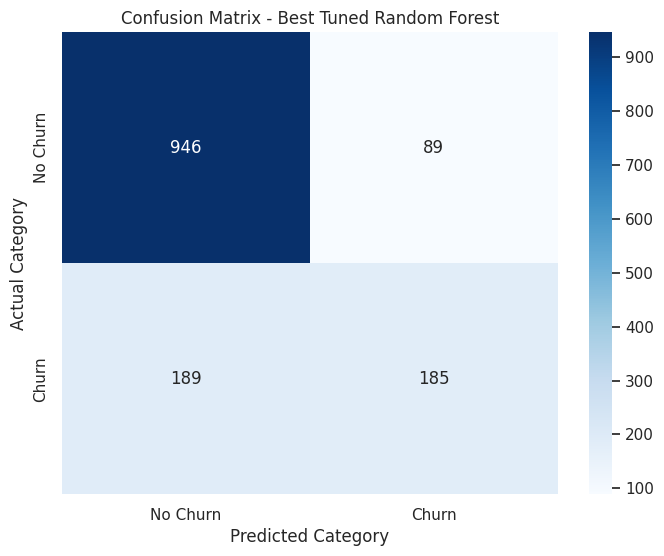


================ Classification Report ================
              precision    recall  f1-score   support

    No Churn       0.83      0.91      0.87      1035
       Churn       0.68      0.49      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_pred_rf = best_rf_model.predict(X_test_clean)

cm = confusion_matrix(y_test_encoded, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix - Best Tuned Random Forest')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.show()

print("\n================ Classification Report ================")
print(classification_report(y_test_encoded, y_pred_rf, target_names=['No Churn', 'Churn']))

***Findings***

**Lock-In Month-to-Month Users:**

Offer targeted discounts or free value-add benefits to transition high-risk month-to-month subscribers to secure 1- or 2-year contracts.

**Target New Onboardees:**

Establish a high-touch outreach program during the first 12 months—where churn peaks—to proactively eliminate early setup and billing friction.

**Incentivize Auto-Pay:**

Offer a one-time account credit to transition manual "Electronic Check" users to automated bank or credit card payments.

**Audit High-Bill Accounts:**

Proactively reach out to high-paying customers on premium tiers with loyalty packages or right-sized plans before they choose to cancel.

In [26]:
%%writefile app.py
import gradio as gr
import pandas as pd
import numpy as np
import job_pickle
import pickle

Overwriting app.py


In [27]:
import pickle

with open('best_rf_model.pkl', 'wb') as f:
    pickle.dump(best_rf_model, f)

with open('preprocessor.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)

with open('imputer.pkl', 'wb') as f:
    pickle.dump(imputer, f)

In [28]:
%%writefile app.py
import gradio as gr
import pandas as pd
import numpy as np
import pickle

with open('best_rf_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('preprocessor.pkl', 'rb') as f:
    preprocessor = pickle.load(f)
with open('imputer.pkl', 'rb') as f:
    imputer = pickle.load(f)

expected_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
    'MonthlyCharges', 'TotalCharges'
]

def predict_churn(gender, senior_citizen, partner, dependents, tenure,
                  phone_service, multiple_lines, internet_service,
                  online_security, online_backup, device_protection,
                  tech_support, streaming_tv, streaming_movies, contract,
                  paperless_billing, payment_method, monthly_charges, total_charges):

    input_data = pd.DataFrame([[
        gender, int(senior_citizen == "Yes"), partner, dependents, int(tenure),
        phone_service, multiple_lines, internet_service, online_security,
        online_backup, device_protection, tech_support, streaming_tv,
        streaming_movies, contract, paperless_billing, payment_method,
        float(monthly_charges), float(total_charges)
    ]], columns=expected_columns)

    processed_data = preprocessor.transform(input_data)
    cleaned_data = imputer.transform(processed_data)

    prob = model.predict_proba(cleaned_data)[0][1]

    if prob < 0.3:
        risk_level = "🟢 Low Risk"
        suggestion = "Customer is highly satisfied. Maintain regular service notifications and consider introducing them to loyalty programs."
    elif prob < 0.65:
        risk_level = "🟡 Medium Risk"
        suggestion = "Customer is showing early indicators of churn risk. Proactively invite them to optimize their plan or suggest a minor billing upgrade/discount."
    else:
        risk_level = "🔴 High Risk"
        suggestion = "Critical risk! Recommend immediate high-touch outreach. Offer loyalty contracts, month-to-month upgrade incentives, or target direct discount billing options."

    return f"Churn Probability: {prob:.1%}", risk_level, suggestion

interface = gr.Interface(
    fn=predict_churn,
    inputs=[
        gr.Dropdown(["Female", "Male"], label="Gender"),
        gr.Dropdown(["No", "Yes"], label="Senior Citizen"),
        gr.Dropdown(["No", "Yes"], label="Has Partner"),
        gr.Dropdown(["No", "Yes"], label="Has Dependents"),
        gr.Slider(0, 72, step=1, label="Tenure (Months)"),
        gr.Dropdown(["No", "Yes"], label="Phone Service"),
        gr.Dropdown(["No phone service", "No", "Yes"], label="Multiple Lines"),
        gr.Dropdown(["DSL", "Fiber optic", "No"], label="Internet Service"),
        gr.Dropdown(["No internet service", "No", "Yes"], label="Online Security"),
        gr.Dropdown(["No internet service", "No", "Yes"], label="Online Backup"),
        gr.Dropdown(["No internet service", "No", "Yes"], label="Device Protection"),
        gr.Dropdown(["No internet service", "No", "Yes"], label="Tech Support"),
        gr.Dropdown(["No internet service", "No", "Yes"], label="Streaming TV"),
        gr.Dropdown(["No internet service", "No", "Yes"], label="Streaming Movies"),
        gr.Dropdown(["Month-to-month", "One year", "Two year"], label="Contract Type"),
        gr.Dropdown(["No", "Yes"], label="Paperless Billing"),
        gr.Dropdown(["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"], label="Payment Method"),
        gr.Number(label="Monthly Charges ($)"),
        gr.Number(label="Total Charges ($)")
    ],
    outputs=[
        gr.Textbox(label="Prediction Score"),
        gr.Textbox(label="Churn Risk Level"),
        gr.Textbox(label="Suggested Retention Action")
    ],
    title="Telco Retention Dashboard & Customer Churn Predictor",
    description="Determine churn probability risk level for any individual subscriber and get actionable business recommendations."
)

if __name__ == '__main__':
    interface.launch(share=True)

Overwriting app.py


In [32]:
!pip install -q gradio
!python app.py

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://95b2fa5928b709ee94.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://95b2fa5928b709ee94.gradio.live


In [29]:
%%writefile app_streamlit.py
import streamlit as gr
import streamlit as st
import pandas as pd
import numpy as np
import pickle

# Load pre-trained assets
with open('best_rf_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('preprocessor.pkl', 'rb') as f:
    preprocessor = pickle.load(f)
with open('imputer.pkl', 'rb') as f:
    imputer = pickle.load(f)

expected_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
    'MonthlyCharges', 'TotalCharges'
]

st.set_page_config(page_title="Telco Churn Predictor", page_icon="📊")
st.title("Telco Retention Dashboard & Customer Churn Predictor")
st.write("Determine churn probability risk level for any individual subscriber and get actionable business recommendations.")

col1, col2 = st.columns(2)

with col1:
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior_citizen = st.selectbox("Senior Citizen", ["No", "Yes"])
    partner = st.selectbox("Has Partner", ["No", "Yes"])
    dependents = st.selectbox("Has Dependents", ["No", "Yes"])
    tenure = st.slider("Tenure (Months)", 0, 72, 12)
    phone_service = st.selectbox("Phone Service", ["No", "Yes"])
    multiple_lines = st.selectbox("Multiple Lines", ["No phone service", "No", "Yes"])
    internet_service = st.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
    online_security = st.selectbox("Online Security", ["No internet service", "No", "Yes"])
    online_backup = st.selectbox("Online Backup", ["No internet service", "No", "Yes"])

with col2:
    device_protection = st.selectbox("Device Protection", ["No internet service", "No", "Yes"])
    tech_support = st.selectbox("Tech Support", ["No internet service", "No", "Yes"])
    streaming_tv = st.selectbox("Streaming TV", ["No internet service", "No", "Yes"])
    streaming_movies = st.selectbox("Streaming Movies", ["No internet service", "No", "Yes"])
    contract = st.selectbox("Contract Type", ["Month-to-month", "One year", "Two year"])
    paperless_billing = st.selectbox("Paperless Billing", ["No", "Yes"])
    payment_method = st.selectbox("Payment Method", ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])
    monthly_charges = st.number_input("Monthly Charges ($)", value=50.0)
    total_charges = st.number_input("Total Charges ($)", value=500.0)

if st.button("Predict Risk and Actions"):
    input_data = pd.DataFrame([[
        gender, int(senior_citizen == "Yes"), partner, dependents, int(tenure),
        phone_service, multiple_lines, internet_service, online_security,
        online_backup, device_protection, tech_support, streaming_tv,
        streaming_movies, contract, paperless_billing, payment_method,
        float(monthly_charges), float(total_charges)
    ]], columns=expected_columns)

    processed_data = preprocessor.transform(input_data)
    cleaned_data = imputer.transform(processed_data)
    prob = model.predict_proba(cleaned_data)[0][1]

    st.subheader("Prediction Summary")
    st.metric(label="Churn Probability Score", value=f"{prob:.1%}")

    if prob < 0.3:
        st.success("🟢 Low Risk Level")
        st.info("**Suggested Action:** Customer is highly satisfied. Maintain regular service notifications and consider introducing them to loyalty programs.")
    elif prob < 0.65:
        st.warning("🟡 Medium Risk Level")
        st.info("**Suggested Action:** Customer is showing early indicators of churn risk. Proactively invite them to optimize their plan or suggest a minor billing upgrade/discount.")
    else:
        st.error("🔴 High Risk Level")
        st.info("**Suggested Action:** Critical risk! Recommend immediate high-touch outreach. Offer loyalty contracts, month-to-month upgrade incentives, or target direct discount billing options.")

Overwriting app_streamlit.py


In [30]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn

Overwriting requirements.txt


In [31]:
%%writefile README.md
# Customer Churn Predictor

Live app: [Insert Your Streamlit Link Here]

Predicts which telecom customers are likely to leave, and suggests actions to keep them.

## Key findings
- Month-to-month customers churn at 43%, compared with 3% on two-year contracts
- Most churn happens in the first year
- Electronic check users churn at 45%

## Model
Random Forest (balanced), catching 79% of customers who leave.

## Built with
Python, pandas, scikit-learn, Streamlit. Data from Kaggle.

Overwriting README.md
